# Professional Data Cleaning and Preprocessing Using Python

**Oasis Infobyte (OIBSIP) ? Data Analytics Internship ? Level 1, Task 3 ? Cleaning Data**

## 1. Project introduction

This notebook documents a complete cleaning workflow for a deliberately messy, **synthetic** customer-transaction dataset. Every record is fictional; no real customer or business data is used, and observations must not be interpreted as real-world findings.

**Objective:** identify and document data-quality issues, apply explainable corrections, preserve the original file, and produce a clean dataset and measurable before/after reports.

**Dataset:** fictional transactions with customer ID, age, gender, city, product category, purchase date, quantity, unit price, transaction total, and payment method. It includes missing values, exact duplicates, inconsistent text, malformed dates, impossible numeric values, a mismatched total, and unusually large but potentially valid purchases.

**Why cleaning matters:** missing, duplicated, inconsistent, or invalid values can distort summaries and decisions. Cleaning improves consistency, but does not prove that every remaining value is correct; uncertain outliers are documented rather than automatically removed.

**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn, and Jupyter Notebook.

## 2. Import libraries

In [1]:
from pathlib import Path
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display

working_dir = Path.cwd()
candidate_dirs = [working_dir, *working_dir.parents]
candidate_dirs.extend(base / "DataAnalytics-L1-DataCleaning" for base in [working_dir, *working_dir.parents])
PROJECT_ROOT = next((candidate for candidate in candidate_dirs
    if (candidate / "src" / "data_cleaning.py").is_file()
    and (candidate / "data" / "raw" / "original_dataset.csv").is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not locate the DataAnalytics-L1-DataCleaning project folder")
sys.path.insert(0, str(PROJECT_ROOT))
from src.data_cleaning import (RAW_FILE, CLEAN_FILE, REPORT_DIR, CHART_DIR,
    build_comparison, build_quality_report, clean_dataset,
    count_data_type_issues, count_outliers, create_before_visualizations,
    create_after_visualizations, create_comparison_visualization)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)
sns.set_theme(style="whitegrid")
print("Project folder:", PROJECT_ROOT)

Project folder: C:\Users\HP\OneDrive\Desktop\OIBSIP\DataAnalytics-L1-DataCleaning


## 3. Load dataset and inspect its structure

In [2]:
raw_data = pd.read_csv(RAW_FILE)
display(raw_data.head(10))
display(raw_data.tail(5))
print("Dataset shape:", raw_data.shape)
print("Column names:", raw_data.columns.tolist())
print("Data types:", raw_data.dtypes, sep="\n")
raw_data.info()
display(raw_data.describe(include="all").T)
numerical_columns = raw_data.select_dtypes(include=np.number).columns.tolist()
categorical_columns = raw_data.select_dtypes(exclude=np.number).columns.tolist()
print("Numerical columns:", numerical_columns)
print("Categorical/text columns:", categorical_columns)

,customer_id,age,gender,city,product_category,purchase_date,quantity,unit_price,total_amount,payment_method
0,C001,24.0,Male,New York,Electronics,2025-01-03,1,899.99,899.99,Card
1,C002,31.0,female,los angeles,Clothing,01/05/2025,2,49.50,99.00,cash
2,C003,45.0,F,Chicago,Home,2025-01-07,1,120.00,120.00,Card
3,C004,NaN,Male,Houston,Beauty,2025-01-09,3,18.75,56.25,Wallet
4,C005,29.0,M,New York,Clothing,2025-01-11,1,75.00,75.00,Card
5,C006,38.0,Female,Los Angeles,Electronics,2025-01-13,1,1299.00,1299.00,Cash
6,C007,52.0,Male,Chicago,Home,2025-01-15,2,210.00,420.00,Card
7,C008,33.0,Female,Houston,Beauty,2025-01-17,4,12.50,50.00,Wallet
8,C009,27.0,Male,NYC,Clothing,2025-01-19,2,45.00,90.00,Cash
9,C010,41.0,F,Chicago,Electronics,2025-01-21,1,699.00,699.00,Card


,customer_id,age,gender,city,product_category,purchase_date,quantity,unit_price,total_amount,payment_method
49,C050,34.0,Male,Chicago,Clothing,2025-04-12,2,55.0,110.0,Cash
50,C007,52.0,Male,Chicago,Home,2025-01-15,2,210.0,420.0,Card
51,C014,30.0,Female,Chicago,Clothing,2025-01-29,2,39.0,78.0,Cash
52,C029,42.0,Male,Chicago,Electronics,2025-03-01,1,599.0,599.0,Card
53,C050,34.0,Male,Chicago,Clothing,2025-04-12,2,55.0,110.0,Cash


Dataset shape: (54, 10)
Column names: ['customer_id', 'age', 'gender', 'city', 'product_category', 'purchase_date', 'quantity', 'unit_price', 'total_amount', 'payment_method']
Data types:
customer_id             str
age                 float64
gender                  str
city                    str
product_category        str
purchase_date           str
quantity              int64
unit_price          float64
total_amount        float64
payment_method          str
dtype: object
<class 'pandas.DataFrame'>
RangeIndex: 54 entries, 0 to 53
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customer_id       54 non-null     str    
 1   age               52 non-null     float64
 2   gender            54 non-null     str    
 3   city              54 non-null     str    
 4   product_category  54 non-null     str    
 5   purchase_date     54 non-null     str    
 6   quantity          54 non-null     int64  
 7 

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customer_id,54,50,C007,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,52.0,NaN,NaN,NaN,37.384615,19.414118,-5.0,28.75,34.0,42.25,150.0
gender,54,7,Male,26,NaN,NaN,NaN,NaN,NaN,NaN,NaN
city,54,8,Chicago,16,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product_category,54,6,Clothing,15,NaN,NaN,NaN,NaN,NaN,NaN,NaN
purchase_date,54,50,2025-01-15,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
quantity,54.0,NaN,NaN,NaN,2.055556,3.366969,-2.0,1.0,1.0,2.0,25.0
unit_price,53.0,NaN,NaN,NaN,440.296792,1378.849467,0.0,39.0,120.0,250.0,9999.0
total_amount,53.0,NaN,NaN,NaN,475.296038,1372.650189,-64.0,78.0,145.0,499.0,9999.0
payment_method,53,7,Card,25,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Numerical columns: ['age', 'quantity', 'unit_price', 'total_amount']
Categorical/text columns: ['customer_id', 'gender', 'city', 'product_category', 'purchase_date', 'payment_method']


## 4. Initial data quality report

The report records row and column counts, missing values and percentages, exact duplicates, expected-type mismatches, inconsistent text formatting, invalid values, and IQR outlier counts. The raw date column is text, as expected for an unparsed CSV; its values are checked for parse failures separately. Numeric IQR flags are review signals, not proof of errors.

In [3]:
initial_quality_report = build_quality_report(raw_data)
initial_quality_report.to_csv(REPORT_DIR / "data_quality_report.csv", index=False)
display(initial_quality_report)
print("Missing values by column:", raw_data.isna().sum(), sep="\n")
print("Missing percentage by column:", (raw_data.isna().mean() * 100).round(2), sep="\n")
print("Exact duplicate rows:", int(raw_data.duplicated().sum()))

,Check,Column,Count,Details
0,Dataset size,All,54,Rows in the dataset
1,Column count,All,10,Columns in the dataset
2,Exact duplicate rows,All,4,Rows that exactly match an earlier record
3,Incorrect data type columns,All,1,Expected numeric fields and purchase_date are ...
4,Missing values,customer_id,0,0.00% of rows
5,Missing values,age,2,3.70% of rows
6,Missing values,gender,0,0.00% of rows
7,Missing values,city,0,0.00% of rows
8,Missing values,product_category,0,0.00% of rows
9,Missing values,purchase_date,0,0.00% of rows


Missing values by column:
customer_id         0
age                 2
gender              0
city                0
product_category    0
purchase_date       0
quantity            0
unit_price          1
total_amount        1
payment_method      1
dtype: int64
Missing percentage by column:
customer_id         0.00
age                 3.70
gender              0.00
city                0.00
product_category    0.00
purchase_date       0.00
quantity            0.00
unit_price          1.85
total_amount        1.85
payment_method      1.85
dtype: float64
Exact duplicate rows: 4


## 5. Data visualization before cleaning

In [4]:
create_before_visualizations(raw_data)
print("Before-cleaning charts saved to:", CHART_DIR)

Before-cleaning charts saved to: C:\Users\HP\OneDrive\Desktop\OIBSIP\DataAnalytics-L1-DataCleaning\visualizations


### Missing values by column
This chart counts blank cells in each field. Gaps in required transaction details need explicit imputation or a documented exclusion so they do not silently distort analysis.

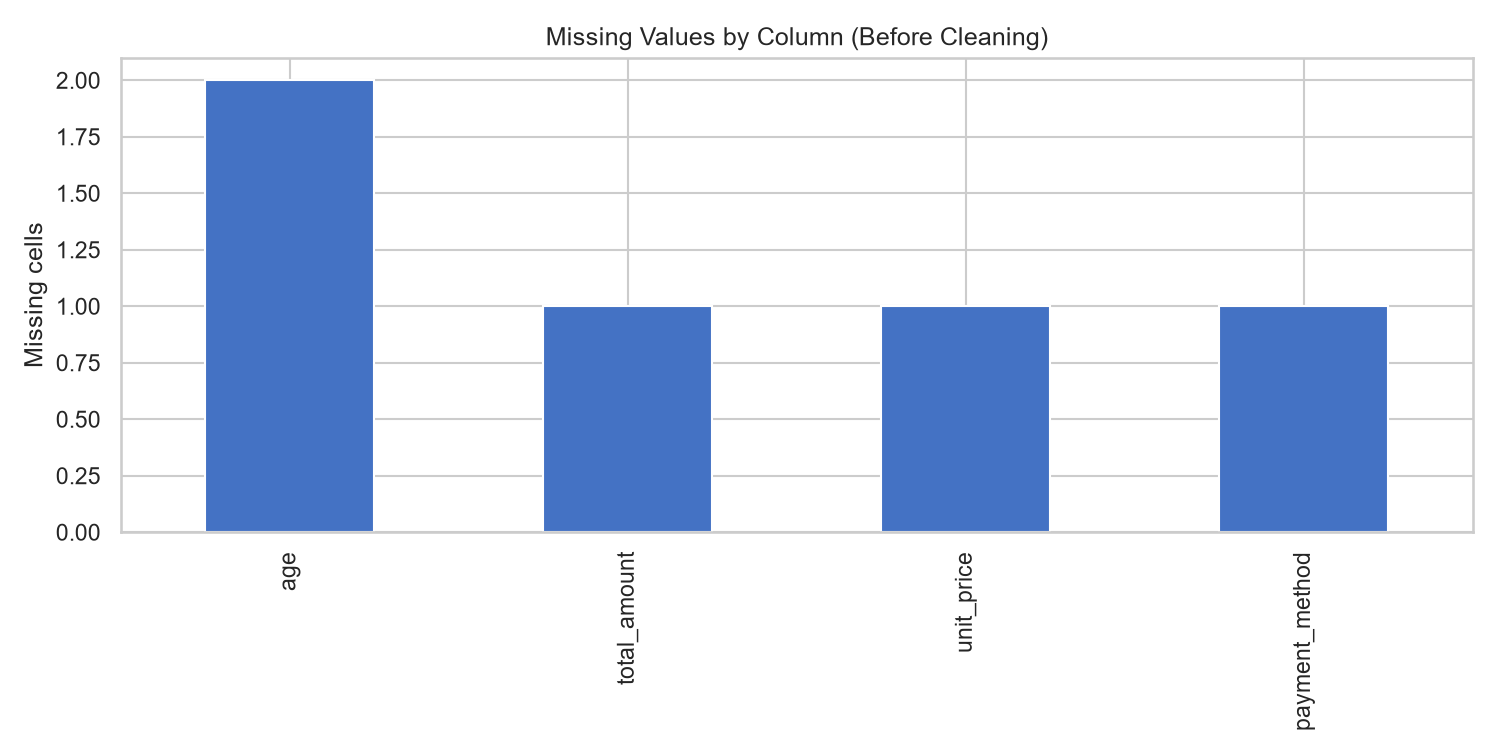

In [5]:
display(Image(filename=str(CHART_DIR / 'missing_values.png')))

The bars show missing cells in age, unit_price, total_amount, and payment_method. Numeric gaps are imputed, the total is recalculated from its components, and categorical gaps use the mode.

### Missing-value heatmap
Each marked cell shows where a value is absent. The pattern helps distinguish isolated gaps from fields with recurring missingness; here, missing cells are a quality concern addressed or documented below.

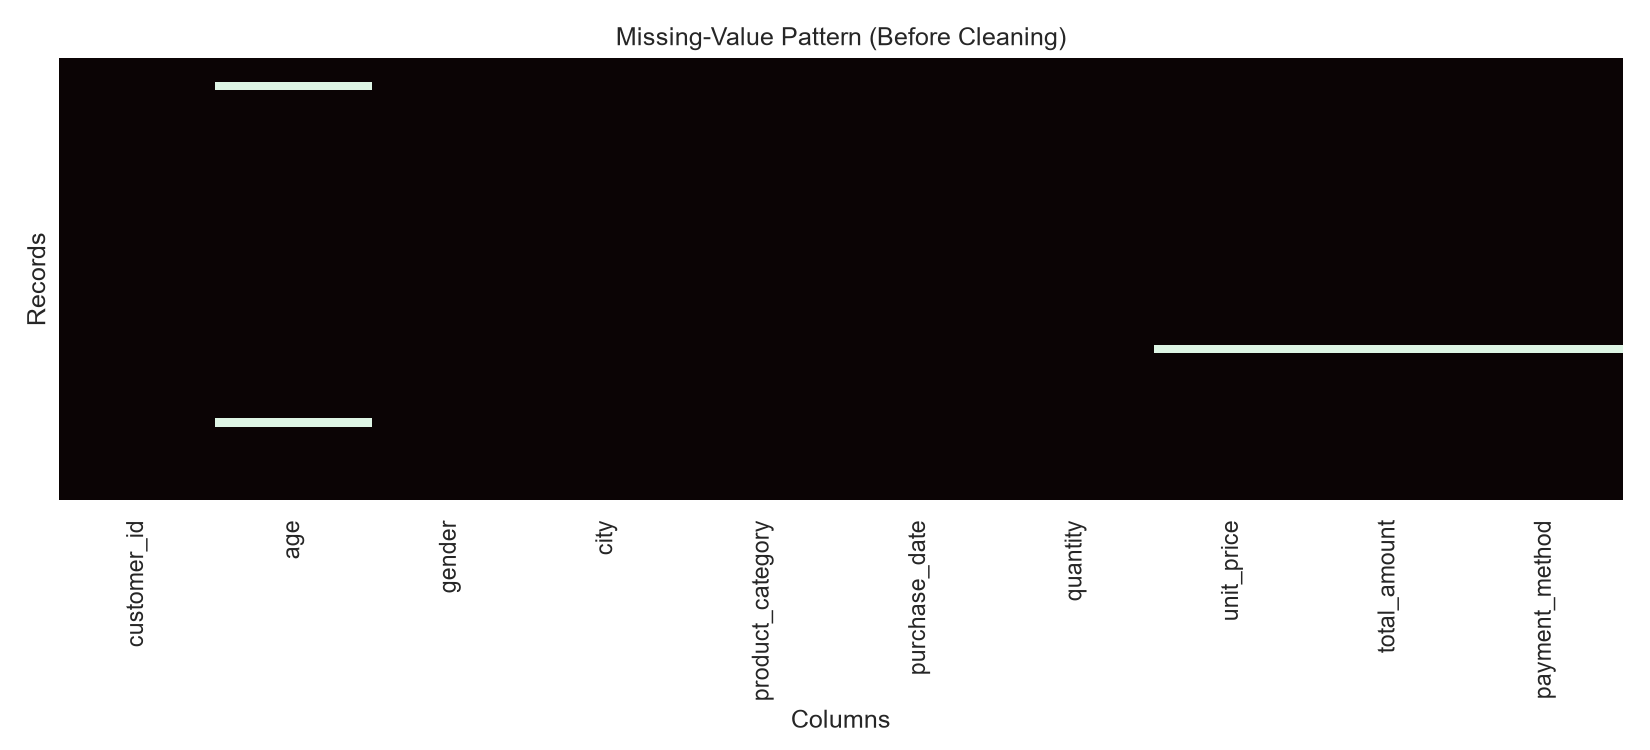

In [6]:
display(Image(filename=str(CHART_DIR / 'missing_values_heatmap.png')))

The heatmap shows the missing cells are sparse rather than a whole missing field. The cleaning steps below address each affected field using its documented method.

### Duplicate record summary
The chart separates exact repeats from distinct rows. Exact duplicate transactions can inflate counts and sums, so they are removed once and counted in the change log.

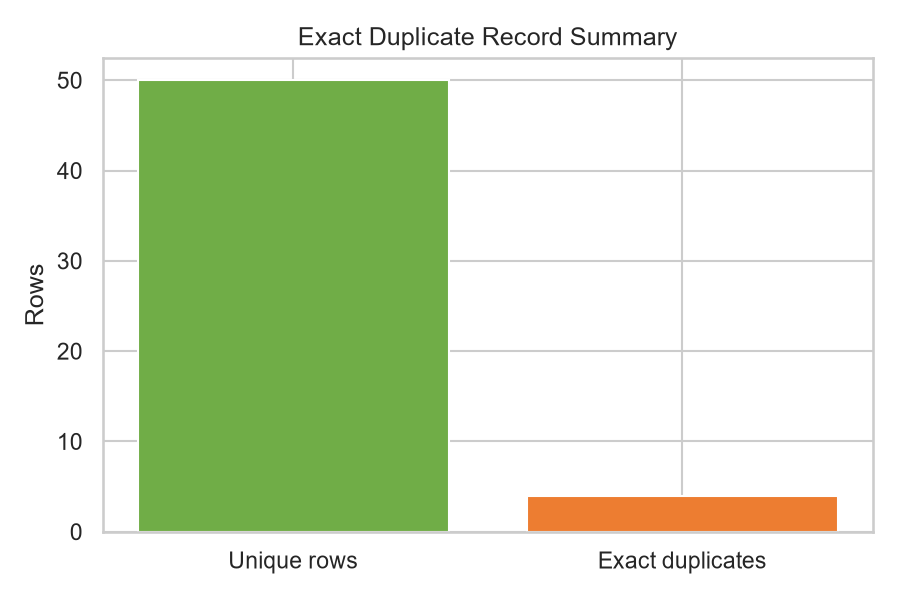

In [7]:
display(Image(filename=str(CHART_DIR / 'duplicate_analysis.png')))

The raw data contains 4 exact duplicate rows among 54 records. Removing those repeats prevents duplicated transactions from inflating counts and totals.

### Numerical distributions
These histograms show the raw distributions of numeric fields. Large values and impossible values require different treatment: invalid values are corrected, while valid extreme observations are retained and flagged for review.

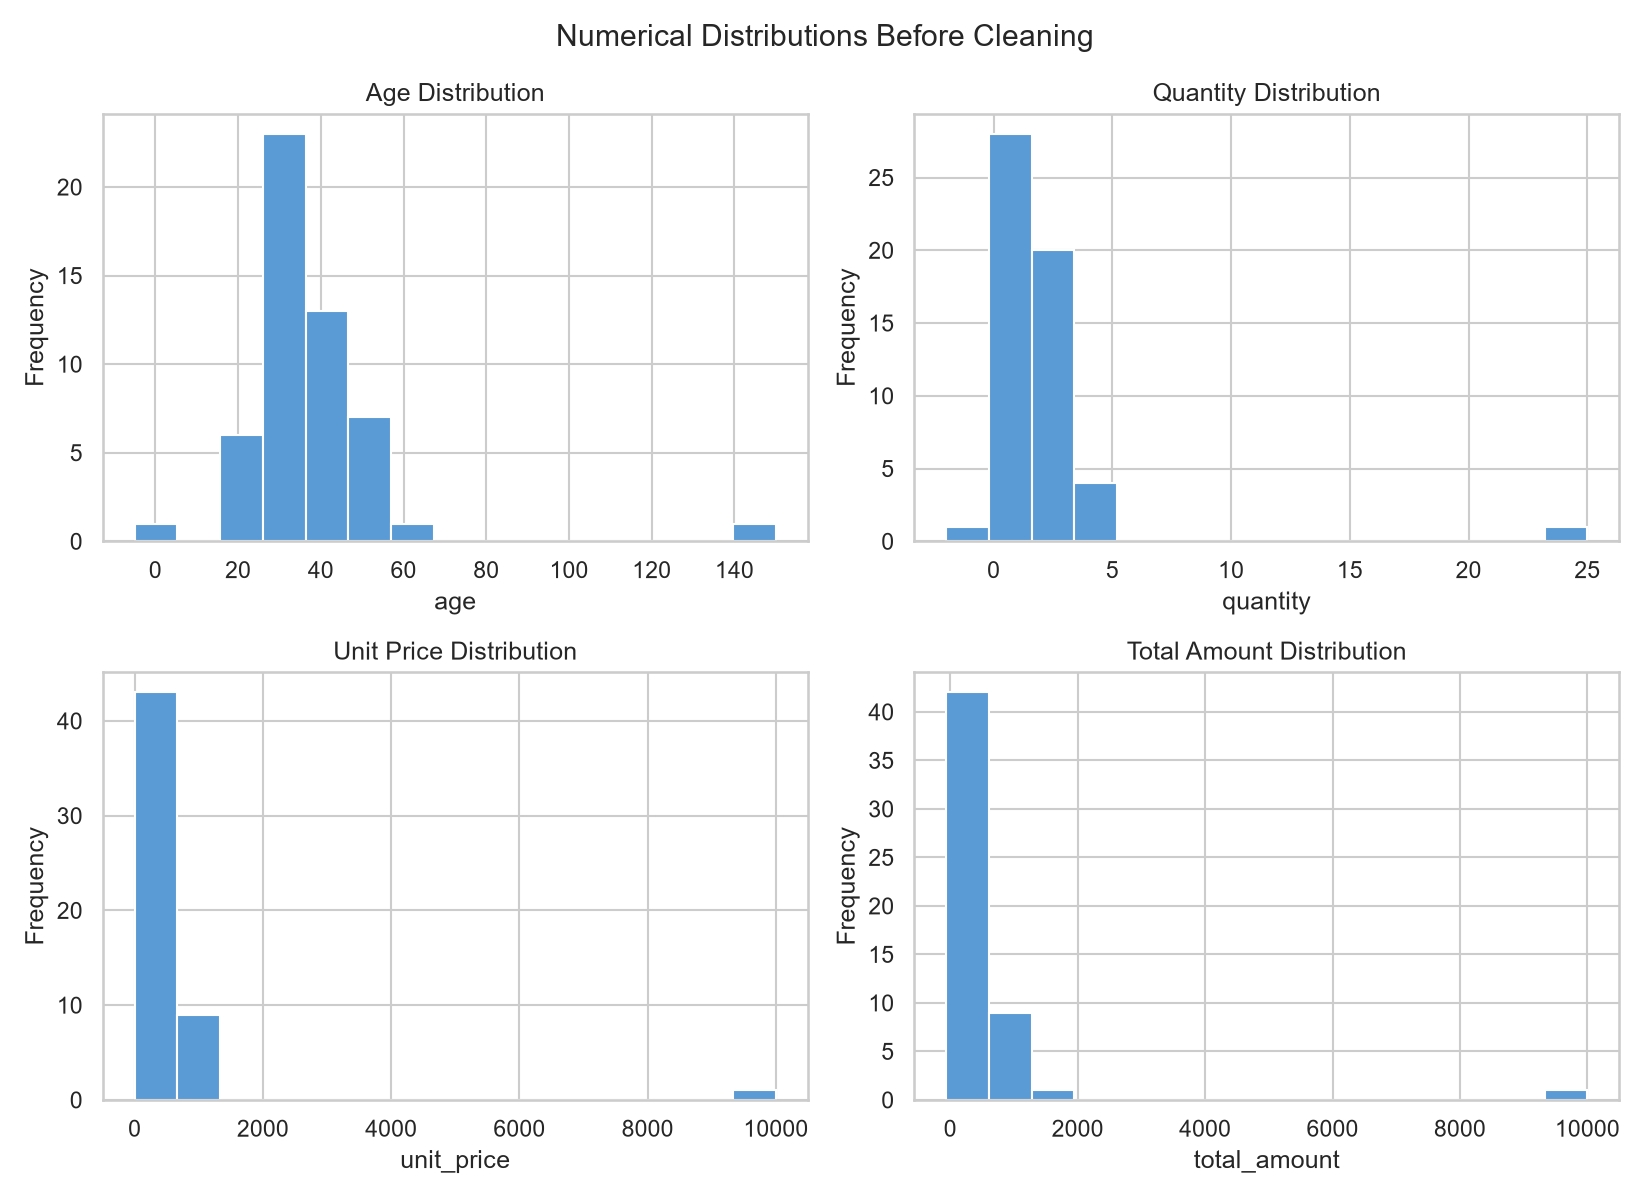

In [8]:
display(Image(filename=str(CHART_DIR / 'numerical_distributions_before.png')))

The distributions include impossible ages and a high unit price. Impossible values are handled as invalid data; plausible extreme purchases are retained for review.

### Outliers before cleaning
The boxplots use the IQR rule to highlight potential extremes. The plot is diagnostic only; valid high-value purchases are not removed just because they lie beyond a statistical fence.

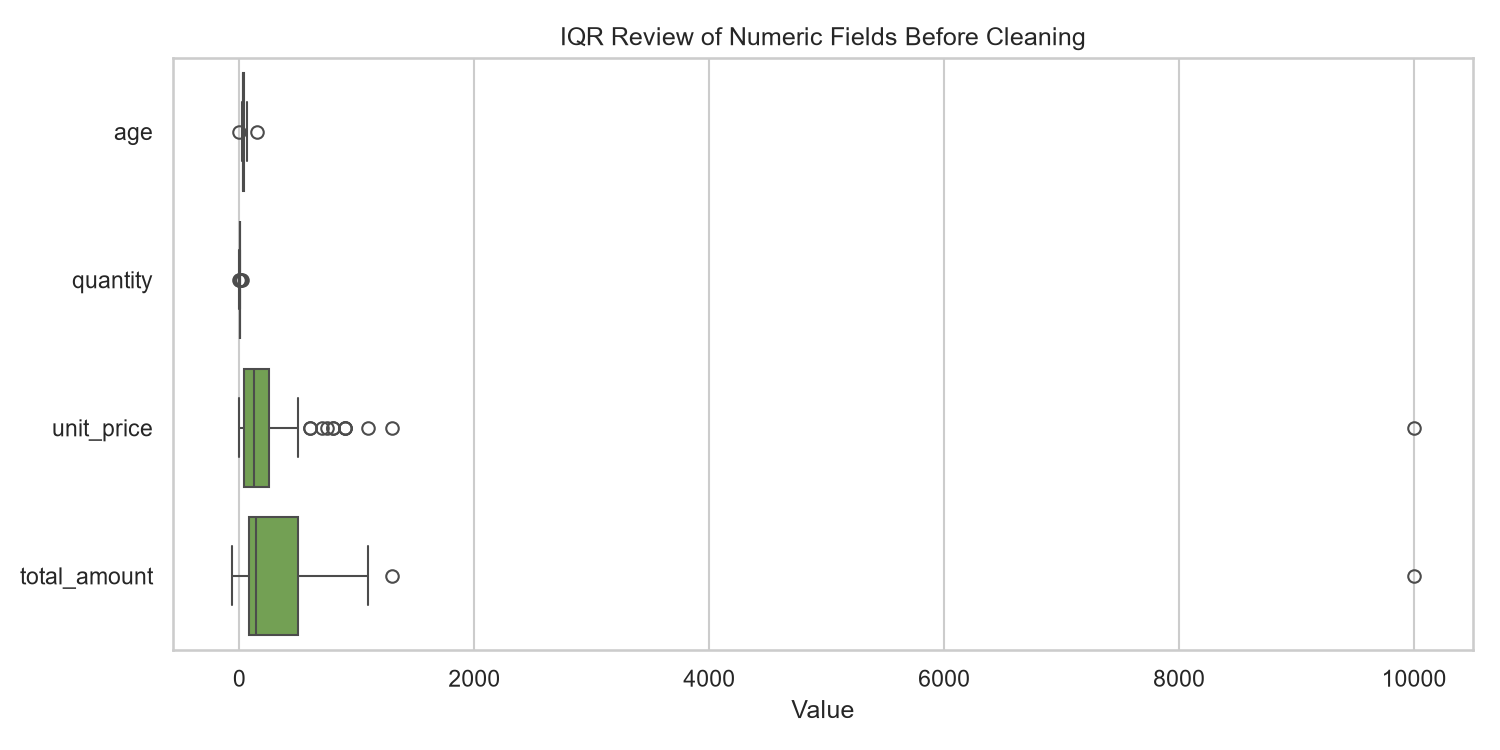

In [9]:
display(Image(filename=str(CHART_DIR / 'outlier_before.png')))

The raw boxplots flag potential extremes, including values that are invalid by business rules. Invalid ages and non-positive values are corrected separately from statistical outlier treatment.

## 6. Missing-value handling

Numeric age, quantity, and unit-price gaps are filled with their medians because medians are less sensitive to skew and extreme valid purchases. Invalid ages (outside 1?100) and non-positive quantities/prices are first treated as missing. Missing category values use the mode. These are independent transactions, so forward fill is not suitable. A row is excluded only when its purchase date cannot be parsed, because its time placement is unknowable.

In [10]:
clean_data, change_log = clean_dataset(raw_data)
print("Values imputed by field:")
display(pd.Series(change_log["imputed_values"], name="Values imputed").to_frame())
print("Invalid values changed to missing:")
display(pd.Series(change_log["invalid_values_marked_missing"], name="Invalid values").to_frame())
print("Rows removed for unparseable dates:", change_log["invalid_date_rows_removed"])

Values imputed by field:


,Values imputed
age,4
quantity,2
unit_price,2
gender,0
city,0
product_category,0
payment_method,1


Invalid values changed to missing:


,Invalid values
age,2
quantity,2
unit_price,1


Rows removed for unparseable dates: 1


## 7. Duplicate removal

In [11]:
duplicate_count = int(raw_data.duplicated().sum())
print("Duplicate rows (excluding first occurrence):", duplicate_count)
display(raw_data[raw_data.duplicated(keep=False)].sort_values("customer_id").head(8))
print("Rows after exact duplicate removal and date validation:", len(clean_data))
print("Duplicate rows remaining:", int(clean_data.duplicated().sum()))

Duplicate rows (excluding first occurrence): 4


,customer_id,age,gender,city,product_category,purchase_date,quantity,unit_price,total_amount,payment_method
6,C007,52.0,Male,Chicago,Home,2025-01-15,2,210.0,420.0,Card
50,C007,52.0,Male,Chicago,Home,2025-01-15,2,210.0,420.0,Card
13,C014,30.0,Female,Chicago,Clothing,2025-01-29,2,39.0,78.0,Cash
51,C014,30.0,Female,Chicago,Clothing,2025-01-29,2,39.0,78.0,Cash
28,C029,42.0,Male,Chicago,Electronics,2025-03-01,1,599.0,599.0,Card
52,C029,42.0,Male,Chicago,Electronics,2025-03-01,1,599.0,599.0,Card
49,C050,34.0,Male,Chicago,Clothing,2025-04-12,2,55.0,110.0,Cash
53,C050,34.0,Male,Chicago,Clothing,2025-04-12,2,55.0,110.0,Cash


Rows after exact duplicate removal and date validation: 49
Duplicate rows remaining: 0


Exact duplicates are removed; the first occurrence is retained. The final row count also reflects the separately documented rows excluded for unparseable dates.

## 8. Data standardization

Whitespace is trimmed and clear text variants are standardized (for example M/male ? Male, NYC ? New York, credit card, debit card, and cc are consistently cased without merging distinct payment types or product categories). These are formatting aliases in this synthetic dataset; distinct city, product, or payment values are not merged without an explicit mapping. Dates are parsed to a single datetime type.

In [12]:
for field in ["gender", "city", "product_category", "payment_method"]:
    print(f"{field} before:", sorted(raw_data[field].dropna().astype(str).unique().tolist()))
    print(f"{field} after: ", sorted(clean_data[field].dropna().astype(str).unique().tolist()))
    print()

gender before: ['F', 'FEMALE', 'Female', 'M', 'Male', 'female', 'male']
gender after:  ['Female', 'Male']

city before: [' Chicago ', ' los angeles ', 'Chicago', 'Houston', 'Los Angeles', 'NYC', 'New York', 'nyc']
city after:  ['Chicago', 'Houston', 'Los Angeles', 'New York']

product_category before: [' electronics ', 'Beauty', 'Clothing', 'Electronics', 'Home', 'Home & Kitchen']
product_category after:  ['Beauty', 'Clothing', 'Electronics', 'Home', 'Home & Kitchen']

payment_method before: [' cash', 'Card', 'Cash', 'Debit Card', 'Wallet', 'cash', 'credit card']
payment_method after:  ['Card', 'Cash', 'Credit Card', 'Debit Card', 'Wallet']



## 9. Outlier detection and treatment

For each numeric field, IQR = Q3 ? Q1; lower bound = Q1 ? 1.5 ? IQR; upper bound = Q3 + 1.5 ? IQR. Impossible values (such as age 150 or negative quantity) are handled as invalid data, separately from outlier treatment. Plausible extreme values are retained because this fictional dataset provides no business evidence that they are errors. Counts below make the remaining review flags explicit.

,Before cleaning,After cleaning
age,2,1
quantity,6,5
unit_price,12,11
total_amount,2,2


Before-treatment boxplot:


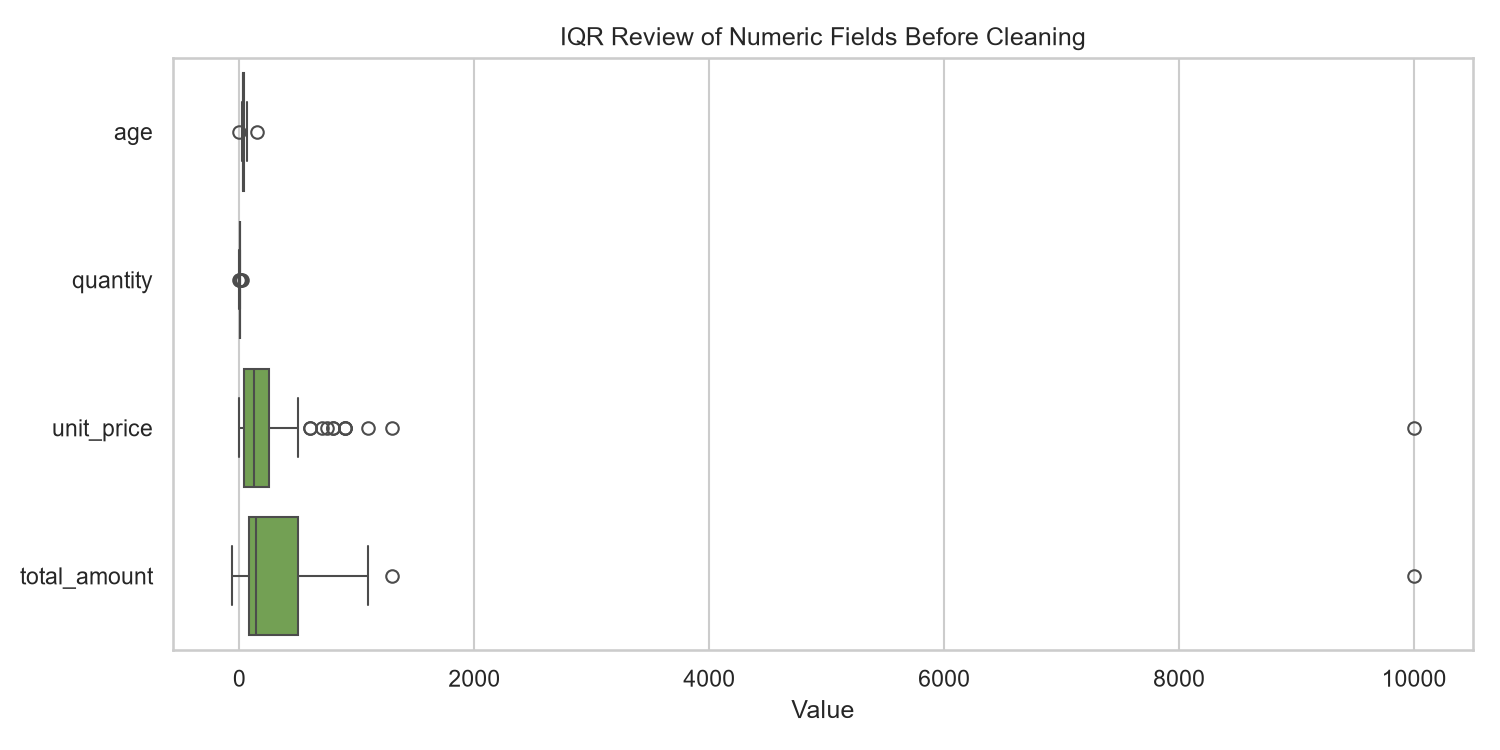

After-treatment boxplot:


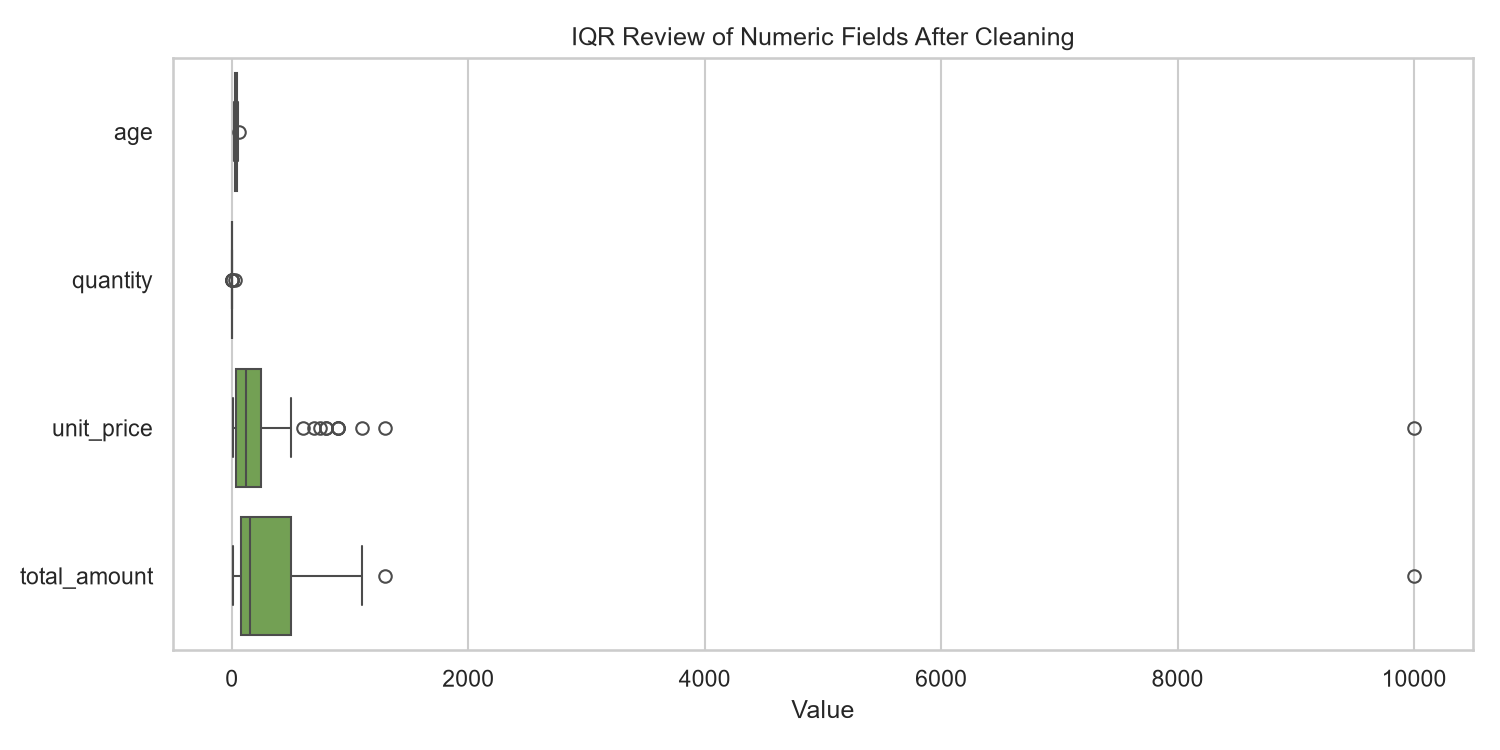

In [13]:
create_after_visualizations(raw_data, clean_data)
outliers_before = count_outliers(raw_data)
outliers_after = count_outliers(clean_data)
outlier_summary = pd.DataFrame({"Before cleaning": outliers_before, "After cleaning": outliers_after})
display(outlier_summary)
print("Before-treatment boxplot:")
display(Image(filename=str(CHART_DIR / "outlier_before.png")))
print("After-treatment boxplot:")
display(Image(filename=str(CHART_DIR / "outlier_after.png")))

The raw boxplots flag potential extremes, including values that are invalid by business rules. Invalid ages and non-positive values are corrected separately from statistical outlier treatment.

## 10. Data type correction

Customer IDs and categorical fields are kept as text, dates are parsed as datetime, age and quantity are nullable integers, and unit price and total are floating-point values. Nullable integer types preserve the integer meaning without converting counts to decimal values.

In [14]:
print(clean_data.dtypes)
print("Parsed date range:", clean_data["purchase_date"].min(), "to", clean_data["purchase_date"].max())

customer_id                 string
age                          Int64
gender                      string
city                        string
product_category            string
purchase_date       datetime64[us]
quantity                     Int64
unit_price                 float64
total_amount               float64
payment_method              string
dtype: object
Parsed date range: 2025-01-03 00:00:00 to 2025-04-12 00:00:00


## 11. Final data validation

The checks below validate the requested invariants. Remaining IQR outliers are documented and intentionally retained; therefore, the result is analysis-ready for the stated use, not claimed to be error-free.

In [15]:
assert clean_data.isna().sum().sum() == 0, "Unexpected missing values remain"
assert not clean_data.duplicated().any(), "Exact duplicates remain"
assert clean_data["purchase_date"].notna().all(), "Unparsed dates remain"
assert clean_data["age"].between(1, 100).all(), "Invalid ages remain"
assert clean_data["quantity"].gt(0).all(), "Non-positive quantities remain"
assert clean_data["unit_price"].gt(0).all(), "Non-positive prices remain"
assert np.allclose(clean_data["total_amount"], clean_data["quantity"] * clean_data["unit_price"]), "Transaction totals do not reconcile"
assert count_data_type_issues(clean_data) == 0, "Data type issues remain"
clean_quality_report = build_quality_report(clean_data)
clean_quality_report.to_csv(REPORT_DIR / "cleaned_data_quality_report.csv", index=False)
print("Validation passed. Remaining IQR outliers are retained and documented.")
display(clean_quality_report)

Validation passed. Remaining IQR outliers are retained and documented.


,Check,Column,Count,Details
0,Dataset size,All,49,Rows in the dataset
1,Column count,All,10,Columns in the dataset
2,Exact duplicate rows,All,0,Rows that exactly match an earlier record
3,Incorrect data type columns,All,0,Expected numeric fields and purchase_date are ...
4,Missing values,customer_id,0,0.00% of rows
5,Missing values,age,0,0.00% of rows
6,Missing values,gender,0,0.00% of rows
7,Missing values,city,0,0.00% of rows
8,Missing values,product_category,0,0.00% of rows
9,Missing values,purchase_date,0,0.00% of rows


## 12. Before-versus-after comparison

,Metric,Before Cleaning,After Cleaning
0,Total rows,54,49
1,Total columns,10,10
2,Missing values,5,0
3,Duplicate rows,4,0
4,Data type issues,1,0
5,IQR outliers,22,19


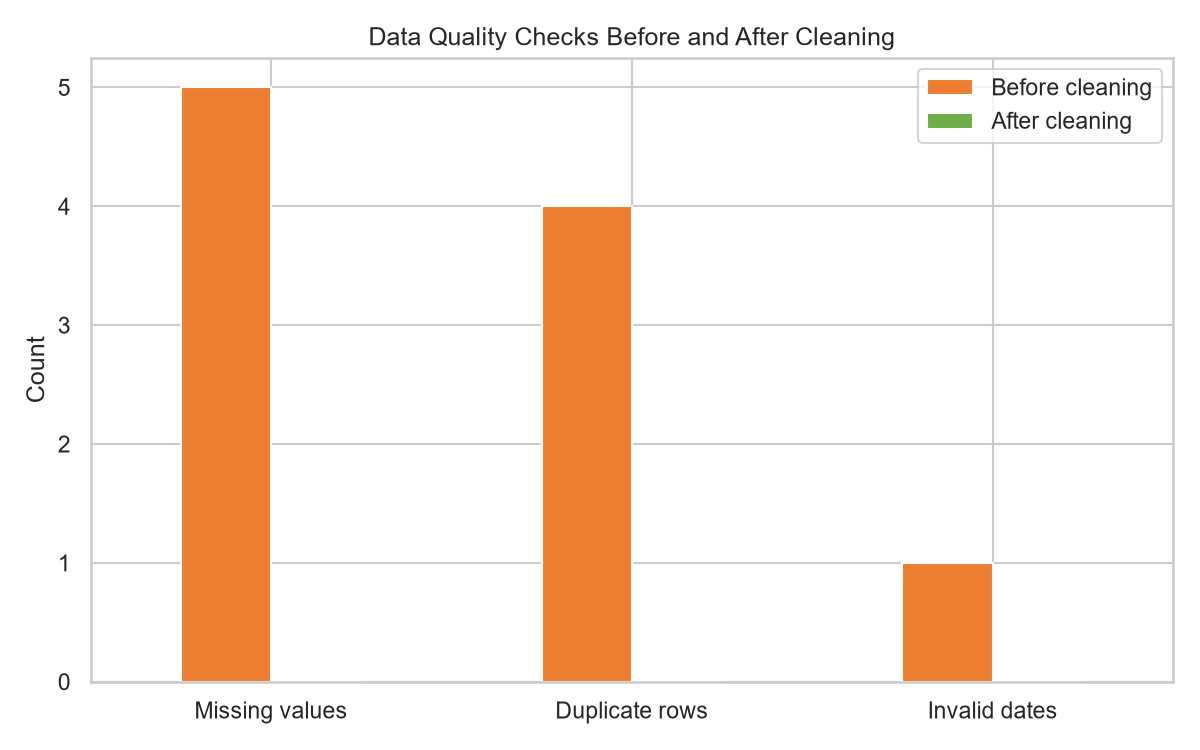

In [16]:
create_comparison_visualization(raw_data, clean_data)
comparison = build_comparison(raw_data, clean_data)
comparison.to_csv(REPORT_DIR / "before_after_comparison.csv", index=False)
display(comparison)
display(Image(filename=str(CHART_DIR / "data_quality_comparison.png")))

The chart shows missing cells falling from 5 to 0, duplicate rows from 4 to 0, and unparseable dates from 1 to 0 after the documented cleaning steps.

The table and chart use metrics calculated from the loaded raw and cleaned data. Outlier counts may remain after cleaning because plausible extremes are retained rather than removed automatically.

## 13. Export cleaned dataset

In [17]:
CLEAN_FILE.parent.mkdir(parents=True, exist_ok=True)
clean_data.to_csv(CLEAN_FILE, index=False)
reloaded_clean_data = pd.read_csv(CLEAN_FILE, parse_dates=["purchase_date"])
print("Exported:", CLEAN_FILE)
print("Reloaded shape:", reloaded_clean_data.shape)
print("Exported columns:", reloaded_clean_data.columns.tolist())

Exported: C:\Users\HP\OneDrive\Desktop\OIBSIP\DataAnalytics-L1-DataCleaning\data\processed\cleaned_dataset.csv
Reloaded shape: (49, 10)
Exported columns: ['customer_id', 'age', 'gender', 'city', 'product_category', 'purchase_date', 'quantity', 'unit_price', 'total_amount', 'payment_method']


The original dataset remains unchanged. The cleaned CSV is exported without a pandas index and is reloaded to verify that the file can be read back.

## 14. Key findings from this cleaning run

In [18]:
missing_before = int(raw_data.isna().sum().sum())
missing_after = int(clean_data.isna().sum().sum())
invalid_numeric_total = sum(change_log["invalid_values_marked_missing"].values())
date_failures = change_log["invalid_date_rows_removed"]
findings = [
    f"The source contains {len(raw_data)} rows and {len(raw_data.columns)} columns; exact duplicate rows removed: {change_log['duplicate_rows_removed']}.",
    f"Missing cells decreased from {missing_before} to {missing_after}; categorical gaps used the mode and numeric gaps used the median.",
    f"{date_failures} row(s) with unparseable dates were excluded so they cannot be placed incorrectly in time-based analysis.",
    f"{invalid_numeric_total} impossible numeric values were converted to missing and imputed; totals were reconciled using quantity ? unit price.",
    f"The combined IQR flag count changed from {sum(outliers_before.values())} to {sum(outliers_after.values())}; plausible extremes were retained for review.",
    f"The final dataset has {len(clean_data)} rows, {len(clean_data.columns)} columns, no missing cells, and no exact duplicates.",
]
for number, finding in enumerate(findings, start=1): print(f"{number}. {finding}")

1. The source contains 54 rows and 10 columns; exact duplicate rows removed: 4.
2. Missing cells decreased from 5 to 0; categorical gaps used the mode and numeric gaps used the median.
3. 1 row(s) with unparseable dates were excluded so they cannot be placed incorrectly in time-based analysis.
4. 5 impossible numeric values were converted to missing and imputed; totals were reconciled using quantity ? unit price.
5. The combined IQR flag count changed from 22 to 19; plausible extremes were retained for review.
6. The final dataset has 49 rows, 10 columns, no missing cells, and no exact duplicates.


## 15. Conclusion

This project inspected and cleaned a fictional transaction dataset by removing exact duplicates, standardizing known text variants, validating and imputing numeric fields, parsing dates, reconciling transaction totals, correcting data types, and documenting potential outliers. The raw input was preserved; the cleaned file, quality reports, and visual evidence are reproducible from the included Python script. In real analytics, these steps reduce avoidable errors and make downstream analysis more trustworthy, while domain review is still needed for uncertain values and interpretations.